# Oligodendrocyte response to mtDSB: who responds, how strongly, and where

Figures and numbers behind `results/sample_classifier/FINDINGS.md`. Every claim there points to a
figure (`results/sample_classifier/figures/`) and a table (`results/sample_classifier/tables/`) written by
this notebook. The notebook never touches the h5ad; it reads:

| input | produced by | where it runs |
|---|---|---|
| `results/region_time/pseudobulk_*.csv` | `scripts/run_region_time_de.py` | office Mac (h5ad) |
| `results/sample_classifier/pseudobulk_general/` | `scripts/run_sample_classifier.py --pseudobulk results/region_time --merge DA-Oligodendrocytes=Oligodendrocytes` | laptop, 3 min |
| `results/sample_classifier/cells_general/` | `scripts/run_sample_classifier.py --h5ad ... --merge DA-Oligodendrocytes=Oligodendrocytes` | office Mac, ~1 h |
| `results/cell_table/` | `scripts/export_cell_table.py --h5ad ...` | office Mac, 1 min |

**Labels.** All models use *general* cell-type labels: the disease-defined cluster `DA-Oligodendrocytes`
is folded into `Oligodendrocytes`, so the treatment effect has to be found by the readouts, not by the
clustering. The cluster is used once, descriptively (readout 3 in section 2).

**Design.** 12 sections = 2 cohorts (DOX removal at P21 or P60) x 2 conditions x 3; all collected 42 days
after induction. One section per animal.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

REPO = Path.cwd().resolve().parent
sys.path.insert(0, str(REPO))
from utils import sample_classifier as sc
from utils import ol_response as olr
from utils.region_time_de import TISSUE_WIDE, Pseudobulk

RES = REPO / "results" / "sample_classifier"
FIG = RES / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = RES / "tables"; TAB.mkdir(parents=True, exist_ok=True)

pb_raw = Pseudobulk.load(REPO / "results" / "region_time")          # original labels (for the cluster readout)
pb = olr.general_pseudobulk(pb_raw)                                  # DA-OL folded into OL
clf_pb = sc.load_results(RES / "pseudobulk_general")
clf_cells = sc.load_results(RES / "cells_general")
sections = pd.read_csv(REPO / "results" / "cell_table" / "sections.csv", index_col=0)
sections["age"] = sections["age"].astype(str)
cell_table = pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz", index_col=0)
# common anatomical orientation for all maps (dorsal up, vertical midline on the right; utils/spatial_orientation.py)
from utils import spatial_orientation as so
orientation = so.fit_orientation(cell_table, reference="RB4405")
orientation.to_csv(REPO / "results" / "cell_table" / "section_orientation.csv")
cell_table = so.apply_orientation(cell_table, orientation)
print("cell types with single-cell results:", sorted(clf_cells["metrics"].cell_type.unique()))

# palette: validated reference palette (dataviz skill); mtDSB responders filled, non-responders hollow
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#f0efec", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
                     "axes.titlesize": 10, "axes.titlelocation": "left"})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")

def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index)
    return df

def stars(p):
    return "***" if p <= 0.001 else "**" if p <= 0.01 else "*" if p <= 0.05 else ""

def group_style(g):
    return {"control": dict(facecolor=BLUE, edgecolor=BLUE),
            "responder": dict(facecolor=ORANGE, edgecolor=ORANGE),
            "non-responder": dict(facecolor="white", edgecolor=ORANGE)}[g]

GROUP_ORDER = ["control", "non-responder", "responder"]

cell types with single-cell results: ['Astrocytes', 'Endothelial Cells', 'Excitatory Neurons', 'GABAergic Neurons', 'Immature Oligodendrocytes I', 'Immature Oligodendrocytes II', 'Immature Oligodendrocytes III', 'Medium Spiny Neurons', 'Microglia', 'Neural Stem Cells', 'Neurons', 'Oligodendrocytes']


## 1. Responder calls from a predefined ISR gene set

Readout 1 uses only prior knowledge: the share of oligodendrocyte transcripts coming from 10 canonical
ATF4 / mitochondrial integrated-stress-response targets (`utils.ol_response.ISR_GENES`, fixed before
looking at the per-section values). A mtDSB section is called a **responder** if its whole-section score is
more than 20% above the *highest* control; otherwise **non-responder**.

In [2]:
isr = olr.isr_scores(pb)
save_table(isr, "isr_scores_by_section_region", index=False)
calls = olr.responder_calls(isr, sections)
sections = calls
save_table(sections, "sections_with_responder_calls")
display(sections[["age", "condition", "sex", "genotype", "n_cells", "isr_cpm", "isr_vs_control_max", "group"]]
        .sort_values("isr_cpm", ascending=False).round(2))

# statistics on the prespecified score (no responder selection involved)
s = sections.assign(log_isr=np.log(sections.isr_cpm))
ctrl, mt = s.loc[s.condition == "control", "log_isr"], s.loc[s.condition == "mtDSB", "log_isr"]
mw = stats.mannwhitneyu(mt, ctrl, alternative="greater")
F = mt.var(ddof=1) / ctrl.var(ddof=1)
p_F = stats.f.sf(F, len(mt) - 1, len(ctrl) - 1)
lev = stats.levene(mt, ctrl, center="median")
isr_stats = pd.DataFrame({
    "test": ["mtDSB > control (Mann-Whitney, one-sided)", "variance mtDSB / control (F, one-sided)", "Brown-Forsythe (Levene, median)"],
    "statistic": [mw.statistic, F, lev.statistic], "p": [mw.pvalue, p_F, lev.pvalue]})
save_table(isr_stats, "isr_group_tests", index=False)
display(isr_stats.round(4))

,age,condition,sex,genotype,n_cells,isr_cpm,isr_vs_control_max,group
sample_id,,,,,,,,
RB4405,60,mtDSB,male,PlptTA:mtPst1,74839,4031.08,1.57,responder
RB4627,21,mtDSB,male,PlptTA:mtPst1,72848,3673.75,1.43,responder
RB4401,60,mtDSB,female,PlptTA:mtPst1,78305,3476.73,1.35,responder
RB4498,60,control,female,PlptTA,75676,2567.84,1.00,control
RB4282,60,control,male,PlptTA,81721,2476.16,0.96,control
RB4350,60,control,male,PlptTA,72889,2456.19,0.96,control
RB4403,60,mtDSB,male,PlptTA:mtPst1,135378,2347.28,0.91,non-responder
RB4630,21,mtDSB,male,PlptTA:mtPst1,69913,2269.02,0.88,non-responder
RB4676,21,control,female,PlptTA,81758,2167.25,0.84,control


,test,statistic,p
0,"mtDSB > control (Mann-Whitney, one-sided)",25.0000,0.1548
1,"variance mtDSB / control (F, one-sided)",9.5781,0.0134
2,"Brown-Forsythe (Levene, median)",38.3220,0.0001


,Atf4,Atf5,Ddit3,Trib3,Gdf15,Sesn2,Fgf21,Psat1,Cth,Eif4ebp1,condition,group
sample_id,,,,,,,,,,,,
RB4282,891.8,141.5,144.8,0.9,0.4,50.3,0.0,1230.1,14.4,2.1,control,control
RB4350,949.6,171.6,145.0,4.4,1.6,65.0,0.6,1101.1,14.7,2.5,control,control
RB4401,1254.9,503.4,256.0,76.8,52.9,132.8,0.6,1169.6,16.4,13.4,mtDSB,responder
RB4403,814.6,179.9,164.4,1.7,0.6,59.1,0.3,1105.1,19.8,1.9,mtDSB,non-responder
RB4405,1800.6,740.5,377.4,181.1,12.7,207.8,0.3,671.3,12.5,26.8,mtDSB,responder
RB4498,869.4,149.2,147.3,1.5,0.6,54.0,0.9,1324.8,19.0,1.3,control,control
RB4620,663.0,135.5,116.8,3.9,0.4,35.8,0.3,1068.8,13.4,1.4,control,control
RB4627,1413.1,662.0,325.1,214.3,65.4,173.5,0.8,782.0,16.4,21.3,mtDSB,responder
RB4630,764.6,150.3,111.7,2.3,0.3,50.5,0.4,1169.8,17.6,1.6,mtDSB,non-responder


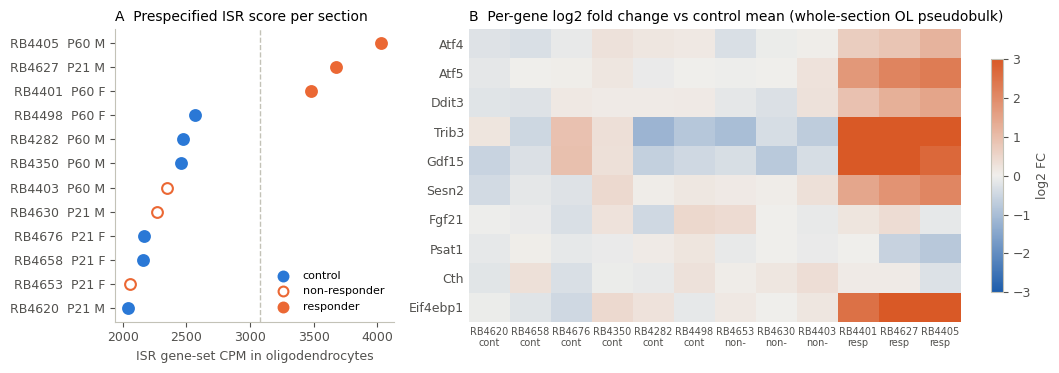

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
ax = axes[0]
order = sections.sort_values("isr_cpm").index
for i, sid in enumerate(order):
    g = sections.loc[sid, "group"]
    ax.scatter(sections.loc[sid, "isr_cpm"], i, s=60, linewidth=1.5, zorder=3, **group_style(g))
ax.axvline(sections.loc[sections.condition == "control", "isr_cpm"].max() * 1.2, color=AXIS, ls="--", lw=1)
ax.set_yticks(range(len(order)), [f"{s}  P{sections.loc[s,'age']} {sections.loc[s,'sex'][0].upper()}" for s in order])
ax.set_xlabel("ISR gene-set CPM in oligodendrocytes")
ax.set_title("A  Prespecified ISR score per section")
for g in GROUP_ORDER:
    ax.scatter([], [], s=50, linewidth=1.5, label=g, **group_style(g))
ax.legend(frameon=False, loc="lower right", fontsize=8)

ax = axes[1]
genes = [g for g in olr.ISR_GENES]
tw = isr[isr.region == TISSUE_WIDE].set_index("sample_id")
ctrl_mean = tw.loc[sections.index[sections.group == "control"], genes].mean()
lfc = np.log2((tw[genes] + 1) / (ctrl_mean + 1))
lfc = lfc.loc[sections.sort_values(["group", "isr_cpm"]).index]
im = ax.imshow(lfc.T.to_numpy(), cmap=LinearSegmentedColormap.from_list("div", ["#1c5cab", "#f0efec", "#d95926"]),
               vmin=-3, vmax=3, aspect="auto")
ax.set_yticks(range(len(genes)), genes)
ax.set_xticks(range(len(lfc)), [f"{s}\n{sections.loc[s,'group'][:4]}" for s in lfc.index], fontsize=7)
ax.set_title("B  Per-gene log2 fold change vs control mean (whole-section OL pseudobulk)")
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="log2 FC")
fig.tight_layout()
save(fig, "F1_isr_responders")
save_table(tw[genes].join(sections[["condition", "group"]]).round(1), "isr_per_gene_whole_section")

## 2. Three independent readouts agree on the same animals

* **ISR score** (prior gene set, section 1)
* **Classifier score**: mean out-of-fold p(mtDSB) of a section's oligodendrocytes from the pooled
  single-cell model (trained on the *other* 11 sections, general labels)
* **Cluster share**: fraction of OLs in the `DA-Oligodendrocytes` cluster (descriptive only)

In [4]:
hf = olr.high_score_fraction(clf_cells["cell_scores"])
save_table(hf, "ol_classifier_scores_by_section_region", index=False)
share = olr.cluster_share(pb_raw)
save_table(share, "da_cluster_share_by_section_region", index=False)

readouts = sections[["age", "condition", "sex", "group", "isr_cpm"]].copy()
readouts["classifier_mean_p"] = hf[hf.region == TISSUE_WIDE].set_index("sample_id")["mean_p"]
readouts["classifier_frac_p>0.8"] = hf[hf.region == TISSUE_WIDE].set_index("sample_id")["frac_high"]
readouts["cluster_share"] = share[share.region == TISSUE_WIDE].set_index("sample_id")["share"]
save_table(readouts, "three_readouts_by_section")
display(readouts.sort_values("isr_cpm", ascending=False).round(3))
rho = readouts[["isr_cpm", "classifier_mean_p", "cluster_share"]].corr(method="spearman")
save_table(rho, "three_readouts_spearman")
display(rho.round(2))
top3 = {c: set(readouts[c].nlargest(3).index) for c in ["isr_cpm", "classifier_mean_p", "cluster_share"]}
print("top-3 sections per readout:", top3)
print("P(top 3 of 12 all mtDSB | random labels) =", round(20 / 220, 3))

,age,condition,sex,group,isr_cpm,classifier_mean_p,classifier_frac_p>0.8,cluster_share
sample_id,,,,,,,,
RB4405,60,mtDSB,male,responder,4031.081,0.805,0.709,0.647
RB4627,21,mtDSB,male,responder,3673.751,0.609,0.455,0.426
RB4401,60,mtDSB,female,responder,3476.727,0.677,0.527,0.215
RB4498,60,control,female,control,2567.842,0.504,0.306,0.009
RB4282,60,control,male,control,2476.160,0.604,0.432,0.003
RB4350,60,control,male,control,2456.192,0.516,0.327,0.023
RB4403,60,mtDSB,male,non-responder,2347.277,0.278,0.132,0.005
RB4630,21,mtDSB,male,non-responder,2269.016,0.370,0.192,0.003
RB4676,21,control,female,control,2167.254,0.382,0.179,0.015


,isr_cpm,classifier_mean_p,cluster_share
isr_cpm,1.00,0.71,0.56
classifier_mean_p,0.71,1.00,0.59
cluster_share,0.56,0.59,1.00


top-3 sections per readout: {'isr_cpm': {'RB4401', 'RB4405', 'RB4627'}, 'classifier_mean_p': {'RB4401', 'RB4405', 'RB4627'}, 'cluster_share': {'RB4401', 'RB4405', 'RB4627'}}
P(top 3 of 12 all mtDSB | random labels) = 0.091


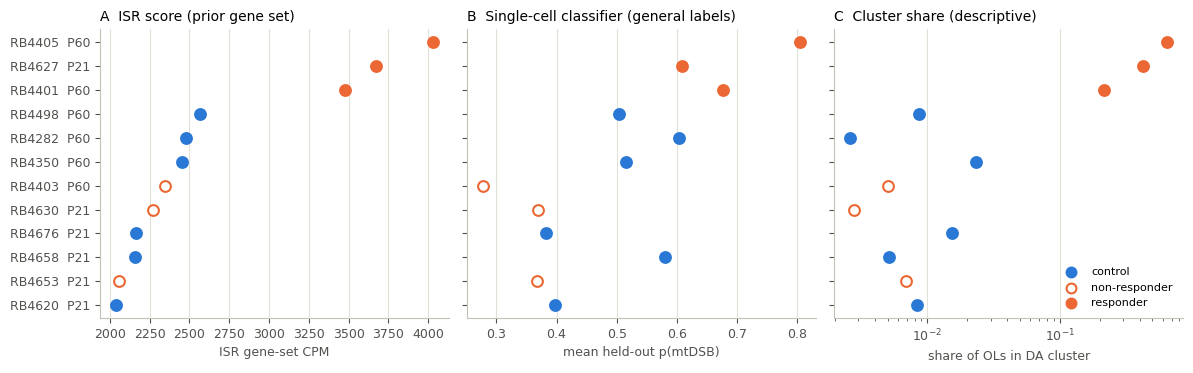

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
order = readouts.sort_values("isr_cpm").index
specs = [("isr_cpm", "ISR gene-set CPM", "A  ISR score (prior gene set)"),
         ("classifier_mean_p", "mean held-out p(mtDSB)", "B  Single-cell classifier (general labels)"),
         ("cluster_share", "share of OLs in DA cluster", "C  Cluster share (descriptive)")]
for ax, (col, xl, title) in zip(axes, specs):
    for i, sid in enumerate(order):
        ax.scatter(readouts.loc[sid, col], i, s=60, linewidth=1.5, zorder=3, **group_style(readouts.loc[sid, "group"]))
    ax.set_xlabel(xl); ax.set_title(title)
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
axes[2].set_xscale("log")
axes[0].set_yticks(range(len(order)), [f"{s}  P{readouts.loc[s,'age']}" for s in order])
for g in GROUP_ORDER:
    axes[2].scatter([], [], s=50, linewidth=1.5, label=g, **group_style(g))
axes[2].legend(frameon=False, loc="lower right", fontsize=8)
fig.tight_layout()
save(fig, "F2_three_readouts")

## 3. Why the plain "mtDSB vs control" classifiers fail

Leave-one-section-out AUC per cell type (pseudobulk, permutation p as stars). Age is predictable from
almost every cell type; condition is not, because half of the mtDSB animals carry no OL response. The
section-level predictions (panel B) show the same three animals at the top and the non-responders at the
bottom.

age: 52/101 strata BH-FDR < 0.1; condition: 0/101 strata perm p < 0.05


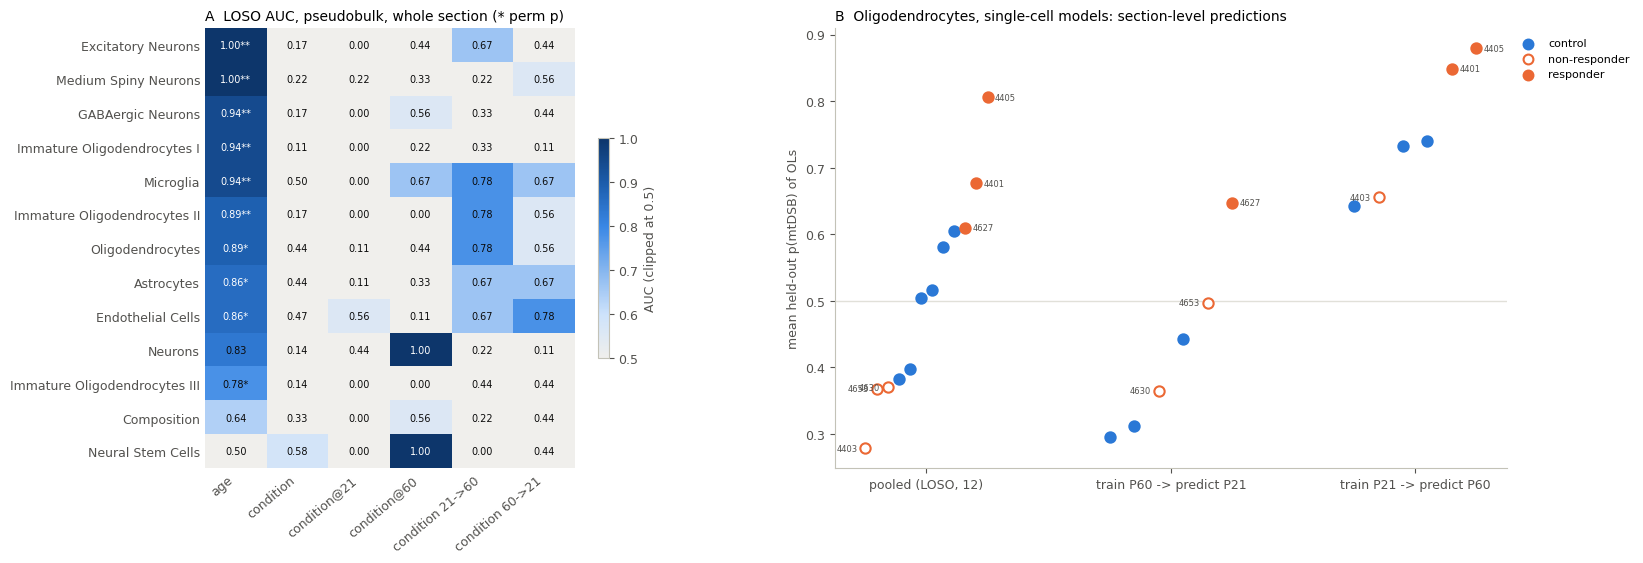

In [6]:
BIN = ["age", "condition", "condition@21", "condition@60", "condition 21->60", "condition 60->21"]
def auc_heatmap(m, rows, cols, title, ax, pcol="perm_p", row_order=None):
    A = m.pivot(index=rows, columns=cols, values="auc")
    A = A[[c for c in BIN if c in A.columns]] if cols == "task" else A
    if row_order is not None:
        A = A.loc[[r for r in row_order if r in A.index]]
    P = m.pivot(index=rows, columns=cols, values=pcol).reindex_like(A) if pcol in m else None
    im = ax.imshow(A.clip(lower=0.5).to_numpy(dtype=float), cmap=SEQ, vmin=0.5, vmax=1.0, aspect="auto")
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            v = A.iat[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}" + (stars(P.iat[i, j]) if P is not None else ""), ha="center", va="center",
                        fontsize=7, color="white" if v > 0.85 else INK)
    ax.set_xticks(range(A.shape[1]), A.columns, rotation=40, ha="right")
    ax.set_yticks(range(A.shape[0]), A.index)
    ax.set_title(title); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    return im

m = clf_pb["metrics"]
tw = m[(m.region == TISSUE_WIDE) & m.task.isin(BIN)]
row_order = tw[tw.task == "age"].sort_values("auc", ascending=False).cell_type.tolist()
fig = plt.figure(figsize=(14, 5.5))
ax1 = fig.add_axes([0.05, 0.12, 0.33, 0.8]); ax2 = fig.add_axes([0.5, 0.12, 0.48, 0.8])
im = auc_heatmap(tw, "cell_type", "task", "A  LOSO AUC, pseudobulk, whole section (* perm p)", ax1, row_order=row_order)
fig.colorbar(im, ax=ax1, shrink=0.5, label="AUC (clipped at 0.5)")

pr = clf_cells["predictions"]
q = pr[(pr.cell_type == olr.OL) & (pr.region == TISSUE_WIDE)]
tasks = ["condition", "condition 60->21", "condition 21->60"]
for k, t in enumerate(tasks):
    qq = q[q.task == t].set_index("sample_id")
    x = k + np.linspace(-0.25, 0.25, len(qq))
    qq = qq.sort_values("p_pos")
    for xi, (sid, row) in zip(x, qq.iterrows()):
        ax2.scatter(xi, row.p_pos, s=55, linewidth=1.5, zorder=3, **group_style(sections.loc[sid, "group"]))
        if sections.loc[sid, "group"] != "control":
            side = 1 if sections.loc[sid, "group"] == "responder" else -1
            ax2.text(xi + side * 0.03, row.p_pos, sid[2:], fontsize=6, color=INK2, va="center",
                     ha="left" if side > 0 else "right")
ax2.set_xticks(range(len(tasks)), ["pooled (LOSO, 12)", "train P60 -> predict P21", "train P21 -> predict P60"])
ax2.axhline(0.5, color=GRID, lw=1); ax2.set_ylabel("mean held-out p(mtDSB) of OLs")
ax2.set_title("B  Oligodendrocytes, single-cell models: section-level predictions")
for g in GROUP_ORDER:
    ax2.scatter([], [], s=50, linewidth=1.5, label=g, **group_style(g))
ax2.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
save(fig, "F3_classifiers")
save_table(tw.pivot(index="cell_type", columns="task", values="auc").round(3), "pseudobulk_auc_whole_section")
save_table(tw.pivot(index="cell_type", columns="task", values="perm_p").round(4), "pseudobulk_permp_whole_section")
save_table(q[q.task.isin(tasks)].pivot(index="sample_id", columns="task", values="p_pos").join(sections["group"]).round(3),
           "ol_cell_model_section_predictions")
age_sig = m[(m.task == "age")]
print(f"age: {(age_sig.padj < 0.1).sum()}/{len(age_sig)} strata BH-FDR < 0.1; condition: "
      f"{(m[m.task=='condition'].perm_p < 0.05).sum()}/{(m.task=='condition').sum()} strata perm p < 0.05")

## 4. Where: the response is brain-wide in responders, strongest in fiber tracts and thalamus

Per region, each readout expressed relative to the mean of the six controls. Regions with < 50 OLs in a
section are left blank.

In [7]:
isr_r = isr[["sample_id", "region", "isr_cpm"]]
ctrl_ids = sections.index[sections.group == "control"]
def rel_to_control(df, value):
    base = df[df.sample_id.isin(ctrl_ids)].groupby("region")[value].mean()
    return df.assign(rel=df[value] / df.region.map(base))
reg_isr = rel_to_control(isr_r[isr_r.region != TISSUE_WIDE], "isr_cpm")
reg_clf = rel_to_control(hf[hf.region != TISSUE_WIDE], "frac_high")
reg_cl = share[share.region != TISSUE_WIDE].rename(columns={"share": "rel"})

summ = pd.concat({
    "ISR (x control)": olr.region_by_group(reg_isr, sections, "rel"),
    "classifier frac p>0.8 (x control)": olr.region_by_group(reg_clf, sections, "rel"),
    "DA cluster share": olr.region_by_group(reg_cl, sections, "rel"),
}, axis=1)
save_table(summ.round(3), "region_summary_by_group")
ranks = pd.concat({
    "ISR": olr.region_rank_per_animal(reg_isr, sections, "rel")["mean rank"],
    "classifier": olr.region_rank_per_animal(reg_clf, sections, "rel")["mean rank"],
    "cluster": olr.region_rank_per_animal(reg_cl, sections, "rel")["mean rank"],
}, axis=1)
ranks["mean over readouts"] = ranks.mean(1)
ranks = ranks.sort_values("mean over readouts")
save_table(ranks.round(2), "region_rank_in_responders")
display(ranks.round(1))

,ISR,classifier,cluster,mean over readouts
region,,,,
Fiber tracts,2.0,2.0,4.0,2.7
Thalamus,2.7,3.7,1.7,2.7
Vasculature,7.3,1.0,4.0,4.1
Striatum,5.3,3.0,5.3,4.6
Hypothalamus,5.0,6.0,3.3,4.8
Cortex,5.7,4.0,5.3,5.0
Ventricular system,4.7,6.7,5.3,5.6
Pallidum,6.5,5.5,8.0,6.7
Meningeal border/glia limitans,5.7,9.3,6.7,7.2


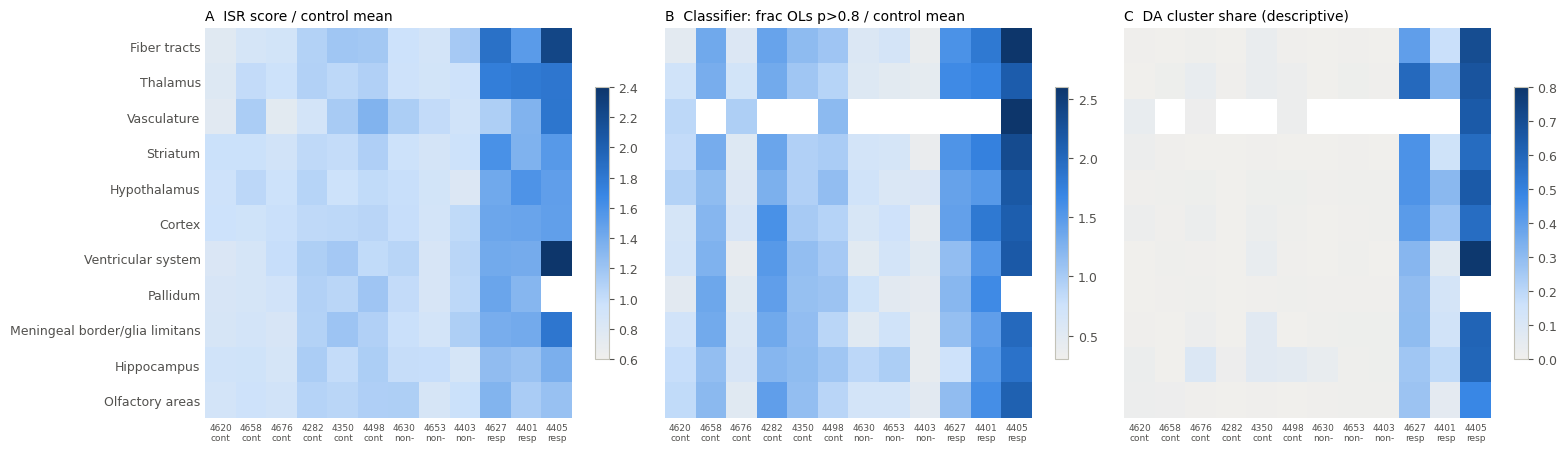

In [8]:
sec_order = sections.sort_values(["group", "age"], key=lambda s: s.map({g: i for i, g in enumerate(GROUP_ORDER)}) if s.name == "group" else s).index
reg_order = ranks.index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
specs = [(reg_isr, "A  ISR score / control mean", 0.6, 2.4),
         (reg_clf, "B  Classifier: frac OLs p>0.8 / control mean", 0.3, 2.6),
         (reg_cl, "C  DA cluster share (descriptive)", 0, 0.8)]
for ax, (df, title, lo, hi) in zip(axes, specs):
    W = df.pivot(index="region", columns="sample_id", values="rel").reindex(index=reg_order, columns=sec_order)
    im = ax.imshow(W.to_numpy(dtype=float), cmap=SEQ, vmin=lo, vmax=hi, aspect="auto")
    ax.set_xticks(range(len(sec_order)), [f"{s[2:]}\n{sections.loc[s,'group'][:4]}" for s in sec_order], fontsize=6.5)
    ax.set_title(title); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    fig.colorbar(im, ax=ax, shrink=0.7)
axes[0].set_yticks(range(len(reg_order)), reg_order)
fig.tight_layout()
save(fig, "F4_regions")

## 5. Spatial maps: oligodendrocyte classifier scores in every section

Light grey: all cells. Mid grey: oligodendrocytes (general label). Orange: oligodendrocytes whose
out-of-fold p(mtDSB) from the pooled model exceeds the 90th percentile of *control* oligodendrocytes
(by construction ~10% of OLs in a control section). The section itself was never in the training set.
Raw probabilities are not shown because the model is poorly calibrated (control OLs also score high).

control 90th percentile of OL p(mtDSB) = 0.979


,group,frac_OL_above_control_p90
sample_id,,
RB4405,responder,0.404
RB4401,responder,0.243
RB4627,responder,0.239
RB4282,control,0.156
RB4658,control,0.144
RB4350,control,0.110
RB4498,control,0.102
RB4630,non-responder,0.058
RB4620,control,0.050


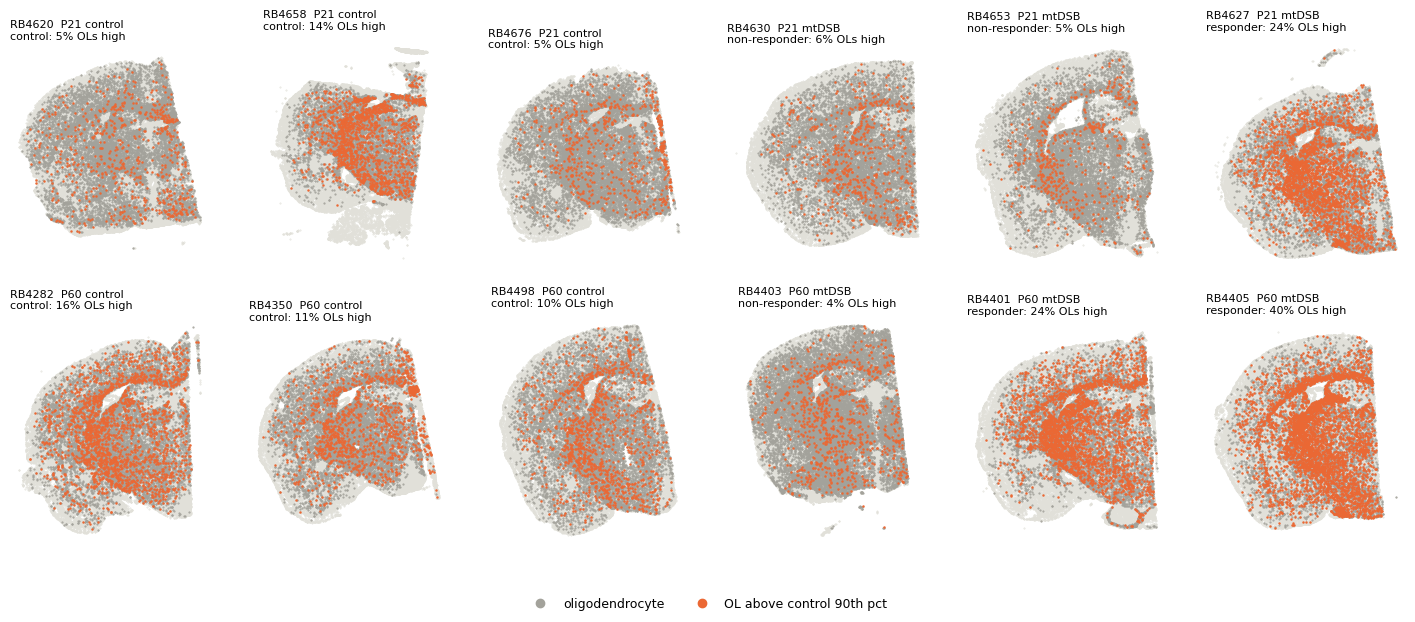

In [9]:
cs = clf_cells["cell_scores"]
ol_scores = cs.loc[cs.cell_type == olr.OL, ["sample_id", "p_pos[condition]"]]
thr = ol_scores.loc[ol_scores.sample_id.isin(ctrl_ids), "p_pos[condition]"].quantile(0.9)
ol_hi = (ol_scores["p_pos[condition]"] > thr).rename("high")
frac90 = ol_hi.groupby(ol_scores.sample_id).mean().rename("frac_OL_above_control_p90")
save_table(sections[["age", "condition", "group"]].join(frac90).round(3), "ol_frac_above_control_p90")
print(f"control 90th percentile of OL p(mtDSB) = {thr:.3f}")
display(sections[["group"]].join(frac90).sort_values("frac_OL_above_control_p90", ascending=False).round(3))
ct = cell_table[["sample_id", "x_oriented", "y_oriented"]].rename(columns={"x_oriented": "x_centroid", "y_oriented": "y_centroid"})
order = sections.sort_values(["age", "group"], key=lambda s: s.map({g: i for i, g in enumerate(GROUP_ORDER)}) if s.name == "group" else s).index
fig, axes = plt.subplots(2, 6, figsize=(18, 6.6))
rng = np.random.default_rng(0)
for ax, sid in zip(axes.ravel(), order):
    c = ct[ct.sample_id == sid]
    bg = c.sample(min(len(c), 40000), random_state=0)
    ax.scatter(bg.x_centroid, bg.y_centroid, s=0.15, color="#e1e0d9", rasterized=True)
    o = c.join(ol_hi, how="inner")
    ax.scatter(o.x_centroid[~o.high], o.y_centroid[~o.high], s=0.3, color="#a3a29b", rasterized=True)
    ax.scatter(o.x_centroid[o.high], o.y_centroid[o.high], s=0.6, color=ORANGE, rasterized=True)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{sid}  P{sections.loc[sid,'age']} {sections.loc[sid,'condition']}\n{sections.loc[sid,'group']}: "
                 f"{100 * frac90[sid]:.0f}% OLs high", fontsize=8)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], ls="", marker="o", color="#a3a29b", label="oligodendrocyte"),
                    Line2D([], [], ls="", marker="o", color=ORANGE, label="OL above control 90th pct")],
           loc="lower center", ncol=2, frameon=False)
save(fig, "F5_spatial_ol_scores")

## 6. Technical checks

* Sex labels vs Xist expression (sample swap check)
* White-matter content per section (section plane)
* Cell counts (RB4403 has ~2x the cells of other sections)

,age,condition,sex,group,n_cells,Xist_cpm,pct_cells_in_fiber_tracts,sex_consistent_with_Xist
sample_id,,,,,,,,
RB4620,21,control,male,control,88718,1.9,8.3,True
RB4658,21,control,female,control,71184,381.4,9.5,True
RB4676,21,control,female,control,81758,398.4,6.7,True
RB4627,21,mtDSB,male,responder,72848,5.2,10.0,True
RB4630,21,mtDSB,male,non-responder,69913,2.3,7.1,True
RB4653,21,mtDSB,female,non-responder,77245,421.2,6.2,True
RB4282,60,control,male,control,81721,0.4,6.8,True
RB4350,60,control,male,control,72889,3.8,5.8,True
RB4498,60,control,female,control,75676,396.6,6.9,True


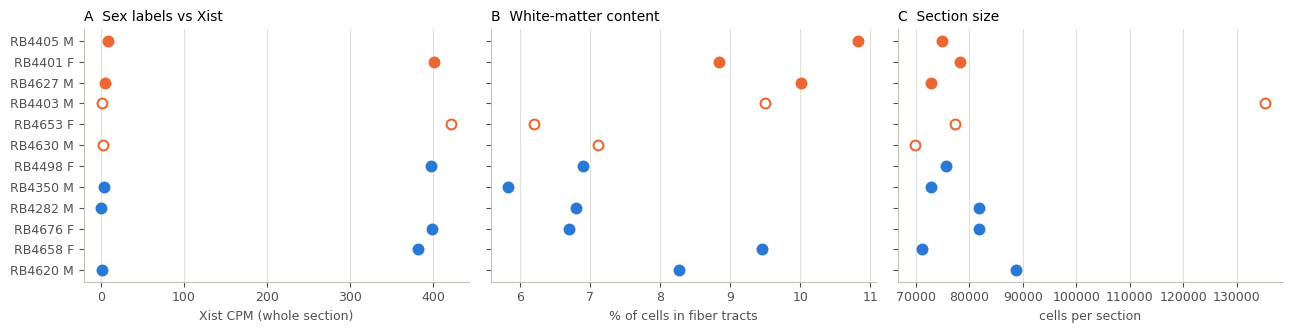

In [10]:
lib = pb.counts.loc[pb.meta.region == TISSUE_WIDE]
by_sec = lib.groupby(pb.meta.loc[lib.index, "sample_id"]).sum()
xist = (by_sec["Xist"] / by_sec.sum(1) * 1e6).rename("Xist_cpm")
meta_all = pd.concat([pb_raw.meta, pb_raw.dropped]); meta_all = meta_all[meta_all.region != TISSUE_WIDE]
meta_all = meta_all.assign(n_cells=meta_all.n_cells.astype(int))
fib = meta_all[meta_all.region == "Fiber tracts"].groupby("sample_id").n_cells.sum()
tot = meta_all.groupby("sample_id").n_cells.sum()
checks = sections[["age", "condition", "sex", "group", "n_cells"]].join(xist)
checks["pct_cells_in_fiber_tracts"] = 100 * fib / tot
checks["sex_consistent_with_Xist"] = np.where(checks.sex == "female", checks.Xist_cpm > 50, checks.Xist_cpm < 50)
save_table(checks.round(2), "technical_checks")
display(checks.round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
order = checks.sort_values(["group", "age"]).index
for ax, col, xl in zip(axes, ["Xist_cpm", "pct_cells_in_fiber_tracts", "n_cells"],
                       ["Xist CPM (whole section)", "% of cells in fiber tracts", "cells per section"]):
    for i, sid in enumerate(order):
        ax.scatter(checks.loc[sid, col], i, s=50, linewidth=1.5, zorder=3, **group_style(checks.loc[sid, "group"]))
    ax.set_xlabel(xl); ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.set_yticks(range(len(order)), [f"{s} {checks.loc[s,'sex'][0].upper()}" for s in order] if ax is axes[0] else [])
axes[0].set_title("A  Sex labels vs Xist"); axes[1].set_title("B  White-matter content"); axes[2].set_title("C  Section size")
fig.tight_layout()
save(fig, "F6_technical_checks")

## 7. Other cell types (single-cell models)

Leave-one-section-out AUC per cell type for the single-cell models (no permutation test at this level).
Weak transfer signals in astrocytes and endothelial cells are listed in FINDINGS.md as hypotheses only.

task                                              condition  condition 21->60  \
cell_type         region                                                        
Astrocytes        All regions                          0.50              0.78   
                  Cortex                               0.47              0.78   
                  Fiber tracts                         0.69              0.78   
                  Hippocampus                          0.50              0.89   
                  Hypothalamus                         0.47              0.67   
                  Meningeal border/glia limitans       0.56              0.78   
                  Olfactory areas                      0.47              0.78   
                  Pallidum                             0.23              0.50   
                  Striatum                             0.42              0.78   
                  Thalamus                             0.36              0.67   
                  Vasculature                          0.42              0.78   
                  Ventricular system                   0.28              0.67   
Endothelial Cells All regions                          0.50              0.78   
                  Cortex                               0.47              0.78   
                  Fiber tracts                         0.64              0.78   
                  Hippocampus                          0.31              0.67   
                  Hypothalamus                         0.50              0.67   
                  Meningeal border/glia limitans       0.72              0.78   
                  Olfactory areas                      0.56              0.78   
                  Pallidum                             0.37              0.67   
                  Striatum                             0.58              0.67   
                  Thalamus                             0.39              0.67   
                  Vasculature                          0.64              0.89   
                  Ventricular system                   0.14              0.56   
Microglia         All regions                          0.44              0.67   
                  Cortex                               0.47              0.89   
                  Fiber tracts                         0.56              0.89   
                  Hippocampus                          0.33              0.78   
                  Hypothalamus                         0.47              0.67   
                  Meningeal border/glia limitans       0.47              0.78   
                  Olfactory areas                      0.39              0.78   
                  Pallidum                             0.25              0.50   
                  Striatum                             0.44              0.67   
                  Thalamus                             0.50              0.67   
                  Vasculature                          0.50              0.50   
                  Ventricular system                   0.33              0.67   

task                                              condition 60->21  
cell_type         region                                            
Astrocytes        All regions                                 0.78  
                  Cortex                                      0.78  
                  Fiber tracts                                0.78  
                  Hippocampus                                 0.67  
                  Hypothalamus                                0.56  
                  Meningeal border/glia limitans              1.00  
                  Olfactory areas                             0.78  
                  Pallidum                                    1.00  
                  Striatum                                    0.67  
                  Thalamus                                    0.56  
                  Vasculature                                 0.78  
                  Ventri

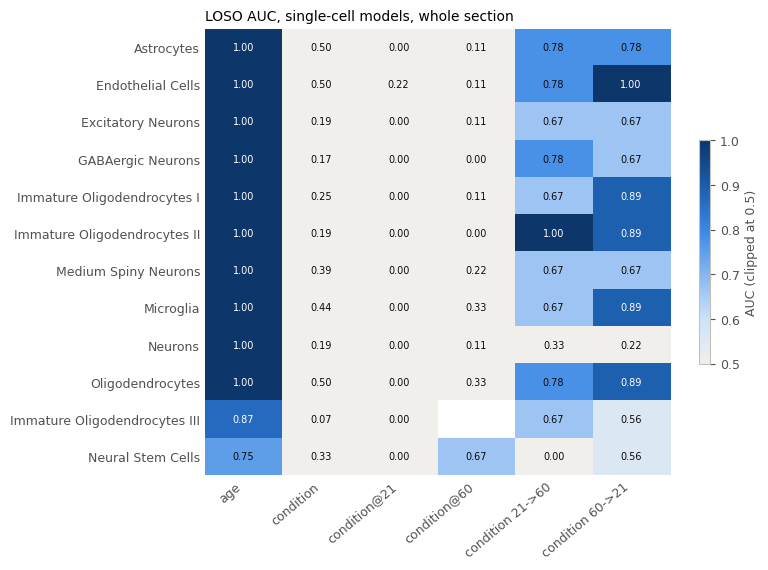

In [11]:
cm = clf_cells["metrics"]
ctw = cm[(cm.region == TISSUE_WIDE) & cm.task.isin(BIN)]
fig, ax = plt.subplots(figsize=(7.5, 5.8))
im = auc_heatmap(ctw, "cell_type", "task", "LOSO AUC, single-cell models, whole section", ax, pcol=None,
                 row_order=ctw[ctw.task == "age"].sort_values("auc", ascending=False).cell_type.tolist())
fig.colorbar(im, ax=ax, shrink=0.5, label="AUC (clipped at 0.5)")
save(fig, "F7_cells_auc_all_cell_types")
save_table(ctw.pivot(index="cell_type", columns="task", values="auc").round(3), "cells_auc_whole_section")

reg_tr = cm[cm.cell_type.isin(["Astrocytes", "Endothelial Cells", "Microglia"]) & cm.task.isin(["condition", "condition 21->60", "condition 60->21"])]
save_table(reg_tr.pivot_table(index=["cell_type", "region"], columns="task", values="auc").round(2), "cells_auc_glia_vascular_by_region")

## 8. The OL mtDSB score itself: distributions and continuous maps

Each oligodendrocyte's out-of-fold p(mtDSB) from the pooled single-cell model, expressed as a **percentile of
control OLs** (pooled over the six controls). This calibrates away the model's general over-confidence: by
construction control OLs are spread evenly over 0-100, so a section whose OLs pile up near 100 has many cells that
look more mtDSB-like than almost any control cell. Panel A: per-mouse distributions; panel B: every OL in every
section coloured by that percentile; the colour scale starts at the 60th percentile so that only cells scoring
higher than most control cells darken (other cells light grey).

,age,condition,group,median,frac_above_90,n_OLs
sample_id,,,,,,
RB4405,60,mtDSB,responder,85.46,0.40,10655
RB4401,60,mtDSB,responder,71.94,0.24,11897
RB4627,21,mtDSB,responder,64.68,0.24,10902
RB4282,60,control,control,63.38,0.16,14198
RB4658,21,control,control,60.67,0.14,10884
RB4350,60,control,control,52.75,0.11,12487
RB4498,60,control,control,51.17,0.10,13303
RB4620,21,control,control,39.27,0.05,13965
RB4676,21,control,control,37.59,0.05,14204


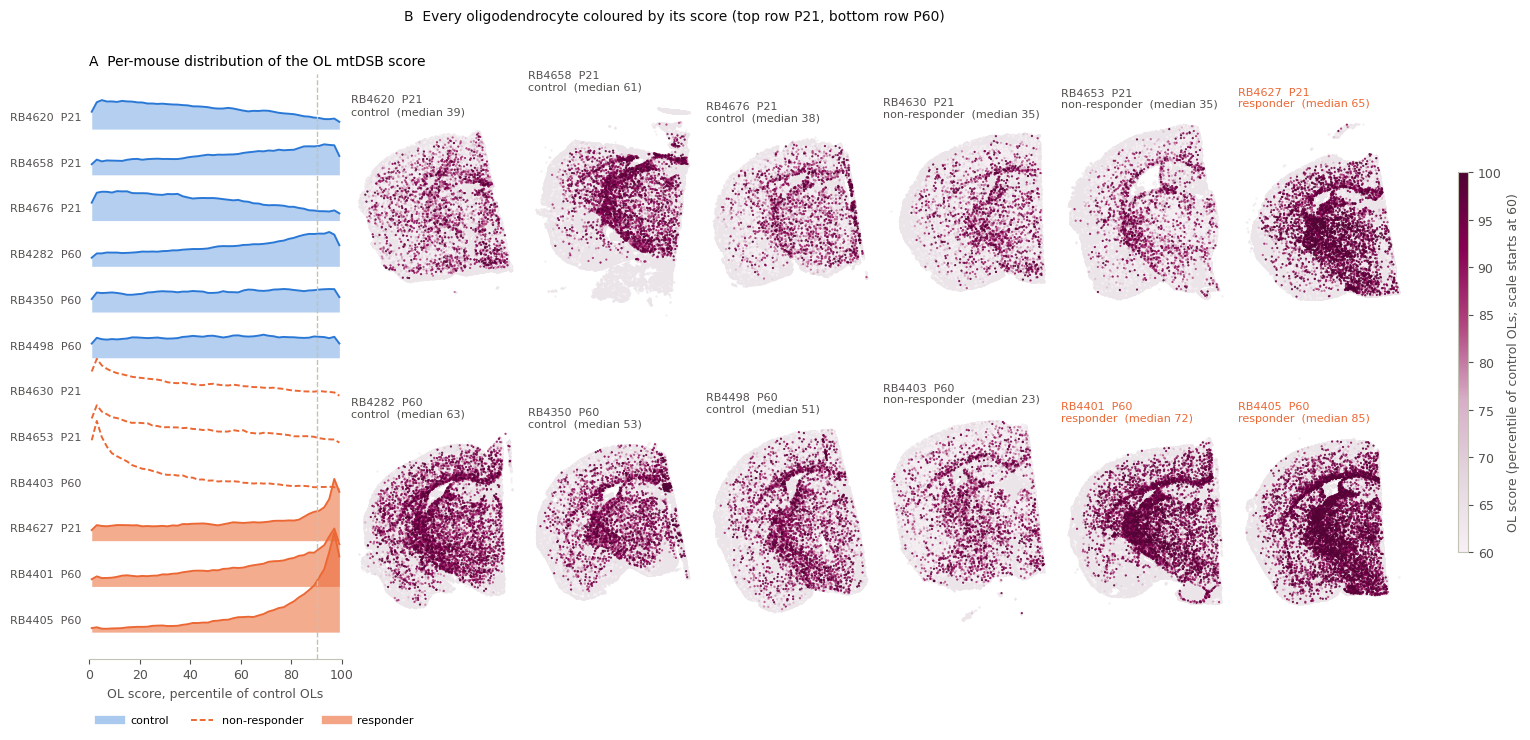

In [12]:
cs = clf_cells["cell_scores"]
ol = cs.loc[cs.cell_type == olr.OL, ["sample_id", "region", "p_pos[condition]"]].dropna().copy()
ctrl_sorted = np.sort(ol.loc[ol.sample_id.isin(ctrl_ids), "p_pos[condition]"].to_numpy())
ol["pct_of_control"] = 100 * np.searchsorted(ctrl_sorted, ol["p_pos[condition]"].to_numpy(), side="right") / len(ctrl_sorted)
score_summary = ol.groupby("sample_id")["pct_of_control"].agg(
    median="median", frac_above_90=lambda v: (v > 90).mean(), n_OLs="size")
score_summary = sections[["age", "condition", "group"]].join(score_summary)
save_table(score_summary.round(3), "ol_score_percentile_by_section")
display(score_summary.sort_values("median", ascending=False).round(2))

PLUMSEQ = LinearSegmentedColormap.from_list("ki_plum", ["#f6f0f4", "#e3d6de", "#d7aec6", "#b0457f", "#870052", "#4f0433"])
order = sections.assign(o=sections.group.map({g: i for i, g in enumerate(GROUP_ORDER)})).sort_values(["o", "age"]).index
fig = plt.figure(figsize=(17, 7.6))
gsp = fig.add_gridspec(2, 7, width_ratios=[1.5, 1, 1, 1, 1, 1, 1], wspace=0.05, hspace=0.12)

# A: ridge of per-mouse distributions
ax = fig.add_subplot(gsp[:, 0])
bins = np.linspace(0, 100, 51)
centers = (bins[:-1] + bins[1:]) / 2
for i, sid in enumerate(order[::-1]):
    v = ol.loc[ol.sample_id == sid, "pct_of_control"].to_numpy()
    d, _ = np.histogram(v, bins=bins, density=True)
    d = np.convolve(d, np.ones(3) / 3, mode="same") * 100 * 0.45
    g = sections.loc[sid, "group"]
    col = {"control": BLUE, "non-responder": ORANGE, "responder": ORANGE}[g]
    ax.fill_between(centers, i, i + d, color=col, alpha={"control": 0.35, "non-responder": 0.0, "responder": 0.55}[g], lw=0)
    ax.plot(centers, i + d, color=col, lw=1.4, ls="-" if g != "non-responder" else (0, (3, 1.5)))
    ax.text(-3, i + 0.15, f"{sid}  P{sections.loc[sid, 'age']}", ha="right", va="bottom", fontsize=8, color=INK2)
ax.axvline(90, color=AXIS, lw=1, ls="--")
ax.set_xlim(0, 100); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_xlabel("OL score, percentile of control OLs")
ax.set_title("A  Per-mouse distribution of the OL mtDSB score")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=BLUE, lw=6, alpha=0.4, label="control"),
                   Line2D([], [], color=ORANGE, lw=1.4, ls=(0, (3, 1.5)), label="non-responder"),
                   Line2D([], [], color=ORANGE, lw=6, alpha=0.6, label="responder")],
          frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3)

# B: continuous maps
ct = cell_table[["sample_id", "x_oriented", "y_oriented"]].rename(columns={"x_oriented": "x_centroid", "y_oriented": "y_centroid"})
map_order = sections.assign(o=sections.group.map({g: i for i, g in enumerate(GROUP_ORDER)})).sort_values(["age", "o"]).index
for k, sid in enumerate(map_order):
    axm = fig.add_subplot(gsp[k // 6, 1 + k % 6])
    c = ct[ct.sample_id == sid]
    bg = c.sample(min(len(c), 40000), random_state=0)
    axm.scatter(bg.x_centroid, bg.y_centroid, s=0.12, color="#ebe4e8", rasterized=True)
    o = c.join(ol["pct_of_control"], how="inner").sort_values("pct_of_control")
    sca = axm.scatter(o.x_centroid, o.y_centroid, c=o["pct_of_control"], s=0.3, cmap=PLUMSEQ, vmin=60, vmax=100, rasterized=True)
    axm.set_aspect("equal"); axm.axis("off")
    g = sections.loc[sid, "group"]
    axm.set_title(f"{sid}  P{sections.loc[sid, 'age']}\n{g}  (median {score_summary.loc[sid, 'median']:.0f})", fontsize=8,
                  color=ORANGE if g == "responder" else INK2)
cax = fig.add_axes([0.93, 0.25, 0.006, 0.5])
fig.colorbar(sca, cax=cax, label="OL score (percentile of control OLs; scale starts at 60)")
fig.text(0.31, 0.95, "B  Every oligodendrocyte coloured by its score (top row P21, bottom row P60)", fontsize=10, color=INK)
save(fig, "F8_ol_score_maps")

## 9. Disease map: the ISR score in every oligodendrocyte

The prespecified ISR score (10 ATF4 / mitochondrial-stress genes, `utils.ol_response.ISR_GENES`; not selected from
these data) per OL, `log1p(1e4 x ISR counts / total counts)` (`scripts/export_ol_gene_scores.py`). Single OLs detect
few ISR transcripts, so for display each OL's score is averaged over its 15 nearest OLs in the same section
(spatial smoothing) and expressed as a percentile of the smoothed control OLs **on the same Xenium slide** (the two slides are the two
age cohorts, and P60 controls have a higher ISR baseline than P21 controls). Panel A: per-mouse distributions
(unsmoothed section means in brackets); panel B: oriented maps (dorsal up, midline right), colour scale from the
60th percentile.

,age,condition,group,isr_mean,isr_pct_median,frac_above_90,myelin_mean,n_OLs
sample_id,,,,,,,,
RB4405,60,mtDSB,responder,3.080,92.618,0.549,5.816,10660
RB4627,21,mtDSB,responder,2.903,91.627,0.537,6.296,10902
RB4401,60,mtDSB,responder,2.734,74.108,0.305,6.487,12373
RB4498,60,control,control,2.529,56.444,0.130,6.698,13304
RB4403,60,mtDSB,non-responder,2.453,49.805,0.082,6.604,23572
RB4282,60,control,control,2.435,49.890,0.097,6.789,14245
RB4350,60,control,control,2.390,43.301,0.072,6.645,12487
RB4676,21,control,control,2.273,58.907,0.134,6.845,14204
RB4630,21,mtDSB,non-responder,2.252,58.671,0.137,6.778,11547


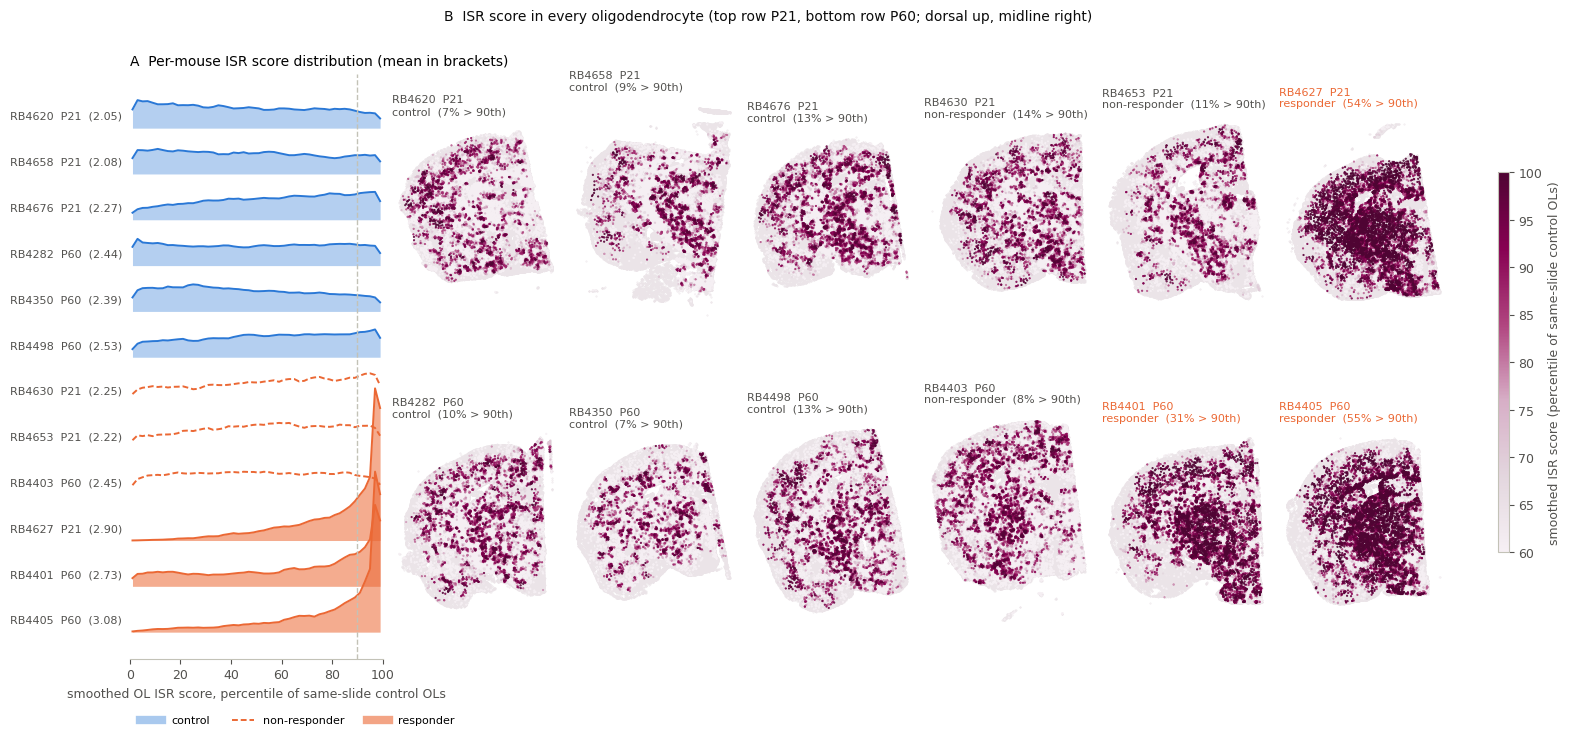

In [13]:
from sklearn.neighbors import NearestNeighbors
gs_cells = pd.read_csv(REPO / "results" / "cell_table" / "ol_gene_scores.csv.gz", index_col=0)
gs_cells = gs_cells.join(cell_table[["x_oriented", "y_oriented"]], how="inner")
K = 15
smooth = pd.Series(np.nan, index=gs_cells.index)
for sid, idx in gs_cells.groupby("sample_id").groups.items():
    sub = gs_cells.loc[idx]
    nn = NearestNeighbors(n_neighbors=K).fit(sub[["x_oriented", "y_oriented"]].to_numpy())
    _, nbr = nn.kneighbors(sub[["x_oriented", "y_oriented"]].to_numpy())
    smooth.loc[idx] = sub["isr"].to_numpy()[nbr].mean(1)
gs_cells["isr_smooth"] = smooth
# percentile against the controls of the same Xenium slide (slide = age cohort here, so this also removes age)
gs_cells["age"] = gs_cells.sample_id.map(sections["age"])
gs_cells["isr_pct"] = np.nan
for age, idx in gs_cells.groupby("age").groups.items():
    sub = gs_cells.loc[idx]
    ref = np.sort(sub.loc[sub.sample_id.isin(ctrl_ids), "isr_smooth"].to_numpy())
    gs_cells.loc[idx, "isr_pct"] = 100 * np.searchsorted(ref, sub["isr_smooth"].to_numpy(), side="right") / len(ref)
isr_summary = sections[["age", "condition", "group"]].join(gs_cells.groupby("sample_id").agg(
    isr_mean=("isr", "mean"), isr_pct_median=("isr_pct", "median"),
    frac_above_90=("isr_pct", lambda v: (v > 90).mean()), myelin_mean=("myelin_down", "mean"), n_OLs=("isr", "size")))
save_table(isr_summary.round(3), "ol_isr_cell_score_by_section")
display(isr_summary.sort_values("isr_mean", ascending=False).round(3))

fig = plt.figure(figsize=(17, 7.6))
gsp = fig.add_gridspec(2, 7, width_ratios=[1.5, 1, 1, 1, 1, 1, 1], wspace=0.05, hspace=0.12)
ax = fig.add_subplot(gsp[:, 0])
bins = np.linspace(0, 100, 51); centers = (bins[:-1] + bins[1:]) / 2
order = sections.assign(o=sections.group.map({g: i for i, g in enumerate(GROUP_ORDER)})).sort_values(["o", "age"]).index
for i, sid in enumerate(order[::-1]):
    v = gs_cells.loc[gs_cells.sample_id == sid, "isr_pct"].to_numpy()
    d, _ = np.histogram(v, bins=bins, density=True)
    d = np.convolve(d, np.ones(3) / 3, mode="same") * 100 * 0.45
    g = sections.loc[sid, "group"]
    col = BLUE if g == "control" else ORANGE
    ax.fill_between(centers, i, i + d, color=col, alpha={"control": 0.35, "non-responder": 0.0, "responder": 0.55}[g], lw=0)
    ax.plot(centers, i + d, color=col, lw=1.4, ls="-" if g != "non-responder" else (0, (3, 1.5)))
    ax.text(-3, i + 0.15, f"{sid}  P{sections.loc[sid, 'age']}  ({isr_summary.loc[sid, 'isr_mean']:.2f})",
            ha="right", va="bottom", fontsize=8, color=INK2)
ax.axvline(90, color=AXIS, lw=1, ls="--")
ax.set_xlim(0, 100); ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_xlabel("smoothed OL ISR score, percentile of same-slide control OLs")
ax.set_title("A  Per-mouse ISR score distribution (mean in brackets)")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=BLUE, lw=6, alpha=0.4, label="control"),
                   Line2D([], [], color=ORANGE, lw=1.4, ls=(0, (3, 1.5)), label="non-responder"),
                   Line2D([], [], color=ORANGE, lw=6, alpha=0.6, label="responder")],
          frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3)
map_order = sections.assign(o=sections.group.map({g: i for i, g in enumerate(GROUP_ORDER)})).sort_values(["age", "o"]).index
for k, sid in enumerate(map_order):
    axm = fig.add_subplot(gsp[k // 6, 1 + k % 6])
    c = cell_table[cell_table.sample_id == sid]
    bg = c.sample(min(len(c), 40000), random_state=0)
    axm.scatter(bg.x_oriented, bg.y_oriented, s=0.12, color="#ebe4e8", rasterized=True)
    o = gs_cells[gs_cells.sample_id == sid].sort_values("isr_pct")
    sca = axm.scatter(o.x_oriented, o.y_oriented, c=o["isr_pct"], s=0.3, cmap=PLUMSEQ, vmin=60, vmax=100, rasterized=True)
    axm.set_aspect("equal"); axm.axis("off")
    g = sections.loc[sid, "group"]
    axm.set_title(f"{sid}  P{sections.loc[sid, 'age']}\n{g}  ({100 * isr_summary.loc[sid, 'frac_above_90']:.0f}% > 90th)",
                  fontsize=8, color=ORANGE if g == "responder" else INK2)
cax = fig.add_axes([0.93, 0.25, 0.006, 0.5])
fig.colorbar(sca, cax=cax, label="smoothed ISR score (percentile of same-slide control OLs)")
fig.text(0.31, 0.95, "B  ISR score in every oligodendrocyte (top row P21, bottom row P60; dorsal up, midline right)",
         fontsize=10, color=INK)
save(fig, "F9_ol_isr_maps")